# 03 · Caracterização e regimes (v2) · RQ1
**CRISP-DM:** Entendimento dos Dados + Modelagem descritiva

1. **Kruskal-Wallis** (com Bonferroni): os indicadores (volume, 4xx, 5xx, latência p95) mudam ao longo das horas do dia?
2. **k-means + silhouette**: quais regimes normais típicos cada recurso tem? O agrupamento usa só os indicadores; o contexto serve depois para nomear os regimes.

O k-means é **descritivo**: a decisão Normal/Residual usa o perfil por contexto (notebook 04).

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v2) carregado · /home/wsl/gh/mestrado/claude9/v2


In [2]:
jan = pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet")
tr = recortar(jan, TREINO)
recursos = sorted(tr["recurso"].unique(), key=rot)
REPRESENTATIVOS = [r for r in recursos if rot(r) in ("E01", "E05", "E12", "E02")]
REPRESENTATIVOS = sorted(REPRESENTATIVOS, key=rot)

## 1. Perfis por hora e tipo de dia

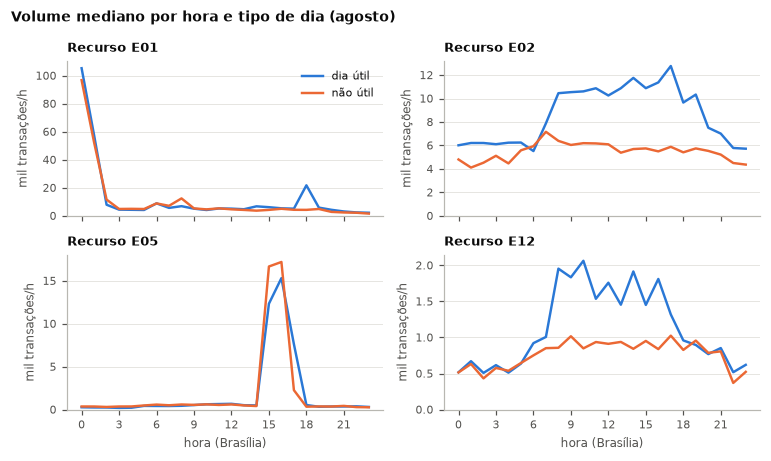

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(7.0, 4.2), sharex=True)
for ax, r in zip(axes.flat, REPRESENTATIVOS):
    g = tr[tr["recurso"] == r].groupby(["tipo_dia", "hora"])["vol"].median().unstack(0) / 1000
    for td in ["util", "nao_util"]:
        ax.plot(g.index, g[td], color=COR_DIA[td], lw=1.6, label=NOMES_DIA[td])
    ax.set_title(f"Recurso {rot(r)}", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.set_ylim(bottom=0)
    ax.set_ylabel("mil transações/h")
    ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.set_xlabel("hora (Brasília)")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Volume mediano por hora e tipo de dia (agosto)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_perfis_volume")
plt.show()

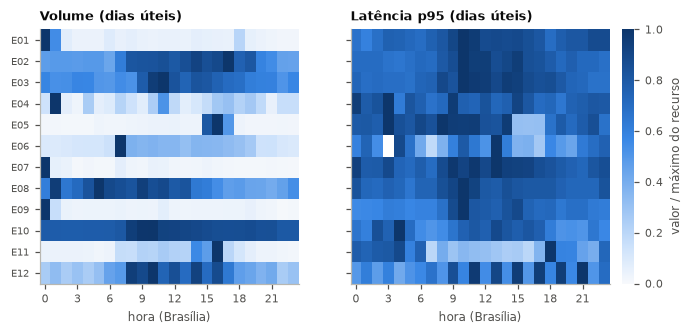

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
ordem = [r for r in recursos]
for ax, (titulo, col, rotulo) in zip(axes, [("Volume (dias úteis)", "vol", "vol"), ("Latência p95 (dias úteis)", "lat_p95", "lat")]):
    m = tr[tr["tipo_dia"] == "util"].groupby(["recurso", "hora"])[col].median().unstack().loc[ordem]
    m = m.div(m.max(axis=1), axis=0)
    im = ax.imshow(m.to_numpy(), aspect="auto", cmap=CMAP_SEQ, vmin=0, vmax=1)
    ax.set_title(titulo, loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hora (Brasília)")
    ax.set_yticks(range(len(m)))
    ax.set_yticklabels([rot(r) for r in m.index], fontsize=6.5)
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
cb.set_label("valor / máximo do recurso", color=TXT2)
cb.outline.set_visible(False)
salvar(fig, "fig_mapa_calor")
plt.show()

## 2. Kruskal-Wallis entre as horas (dias úteis)
Hipótese nula: a distribuição do indicador é a mesma em todas as 24 horas. Correção de **Bonferroni** para os 48 testes (12 recursos × 4 indicadores). Tamanho de efeito ε² = (H − k + 1)/(n − k).

In [5]:
kw = []
for r in recursos:
    u = tr[(tr["recurso"] == r) & (tr["tipo_dia"] == "util")]
    for a in ATRIBUTOS:
        grupos = [v[a].dropna().to_numpy() for _, v in u.groupby("hora")]
        grupos = [g for g in grupos if len(g)]
        if np.ptp(np.concatenate(grupos)) == 0:
            continue
        H, p = stats.kruskal(*grupos)
        n, k = sum(map(len, grupos)), len(grupos)
        kw.append(dict(recurso=rot(r), indicador=INDICADOR[a], H=H, p=p, eps2=(H - k + 1) / (n - k)))
kw = pd.DataFrame(kw)
kw["p_bonf"] = (kw["p"] * len(kw)).clip(upper=1)
kw["sig"] = kw["p_bonf"] < 0.05
tab_kw = kw.pivot(index="recurso", columns="indicador", values="eps2").round(2)
tab_kw["indicadores significativos"] = kw.groupby("recurso")["sig"].sum()
print(f"{kw['sig'].mean():.0%} dos testes significativos (Bonferroni, α = 0,05)")
print("ε² mediano por indicador:", kw.groupby("indicador")["eps2"].median().round(2).to_dict())
tab_kw

85% dos testes significativos (Bonferroni, α = 0,05)
ε² mediano por indicador: {'erros 4xx': 0.35, 'erros 5xx': 0.07, 'latência p95': 0.27, 'volume': 0.39}


indicador,erros 4xx,erros 5xx,latência p95,volume,indicadores significativos
recurso,,,,,
E01,0.28,0.14,0.33,0.54,4
E02,0.24,0.14,0.33,0.23,4
E03,0.53,0.03,0.48,0.61,3
E04,0.30,0.02,0.10,0.34,3
E05,0.24,0.05,0.23,0.40,3
E06,0.82,0.05,0.31,0.77,3
E07,0.24,0.11,0.13,0.23,4
E08,0.53,0.05,0.21,0.08,3
E09,0.24,0.17,0.27,0.38,4


## 3. Regimes por k-means (indicadores de comportamento)

In [6]:
def matriz(g):
    x = g[ATRIBUTOS].copy()
    x["log_lat_p95"] = x["log_lat_p95"].fillna(x["log_lat_p95"].median())
    return x.to_numpy()


def faixas_horas(horas):
    horas = sorted(horas)
    if not horas:
        return ""
    partes, ini, ant = [], horas[0], horas[0]
    for h in horas[1:] + [None]:
        if h is not None and h == ant + 1:
            ant = h
            continue
        partes.append(f"{ini}h" if ini == ant else f"{ini}–{ant}h")
        if h is not None:
            ini = ant = h
    return ", ".join(partes)


def nomear(g, rotulos):
    g = g.assign(regime=rotulos)
    ordem_vol = g.groupby("regime")["vol"].median().rank(method="first")
    k = len(ordem_vol)
    nomes = {}
    for c, gg in g.groupby("regime"):
        nivel = "alto" if ordem_vol[c] > 2 * k / 3 else ("baixo" if ordem_vol[c] <= k / 3 else "médio")
        extras = []
        if gg["tx_4xx"].median() > max(0.05, 2 * g["tx_4xx"].median()):
            extras.append("4xx alto")
        if gg["tx_5xx"].median() > max(0.02, 3 * g["tx_5xx"].median()):
            extras.append("5xx alto")
        if gg["log_lat_p95"].median() > g["log_lat_p95"].median() + 0.4:
            extras.append("latência alta")
        dias = gg["tipo_dia"].value_counts(normalize=True)
        dia = NOMES_DIA[dias.index[0]] if dias.iloc[0] >= 0.7 else "todos os dias"
        frac_hora = g.groupby("hora")["regime"].apply(lambda s: (s == c).mean())
        horas = faixas_horas(list(frac_hora[frac_hora >= 0.5].index)) or "esporádico"
        nomes[int(c)] = f"R{c + 1}: volume {nivel}{', ' + ', '.join(extras) if extras else ''} · {dia} · {horas}"
    return nomes


linhas, nomes_todos, slots = [], {}, []
for r in recursos:
    g = tr[tr["recurso"] == r].reset_index(drop=True)
    x = StandardScaler().fit_transform(matriz(g))
    melhor = None
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(x)
        s = silhouette_score(x, km.labels_)
        if melhor is None or s > melhor[0]:
            melhor = (s, km)
    s, km = melhor
    nomes = nomear(g, km.labels_)
    nomes_todos[rot(r)] = nomes
    linhas.append(dict(recurso=rot(r), k=km.n_clusters, silhouette=round(s, 3)))
    dom = g.assign(regime=km.labels_).groupby(["tipo_dia", "hora"])["regime"].agg(lambda v: v.value_counts().index[0])
    slots.append(dom.rename("regime").reset_index().assign(recurso=r, nome=lambda d: d["regime"].map(nomes)))
regimes = pd.DataFrame(linhas).set_index("recurso")
slots = pd.concat(slots, ignore_index=True)
print("regimes por recurso: mediana", regimes["k"].median(), "· silhouette médio", round(regimes["silhouette"].mean(), 2))
regimes

regimes por recurso: mediana 3.5 · silhouette médio 0.59


,k,silhouette
recurso,,
E01,6,0.452
E02,5,0.538
E03,4,0.580
E04,5,0.441
E05,3,0.592
E06,3,0.685
E07,2,0.884
E08,5,0.383
E09,2,0.849


In [7]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame([(r, n) for r, d in nomes_todos.items() for n in d.values()], columns=["recurso", "regime"]))

,recurso,regime
0,E01,"R1: volume alto · dia útil · 0–1h, 18h"
1,E01,"R2: volume médio · todos os dias · 2–8h, 10h, 12–17h, 19–23h"
2,E01,"R3: volume alto, 5xx alto · não útil · esporádico"
3,E01,"R4: volume médio, latência alta · dia útil · esporádico"
4,E01,"R5: volume baixo, 4xx alto · não útil · esporádico"
5,E01,"R6: volume baixo, 4xx alto · todos os dias · esporádico"
6,E02,R1: volume baixo · não útil · esporádico
7,E02,"R2: volume alto · dia útil · 8–17h, 19h"
8,E02,"R3: volume médio · todos os dias · 3–6h, 20–23h"
9,E02,"R4: volume alto, latência alta · dia útil · esporádico"


### Exemplo: regime predominante por contexto

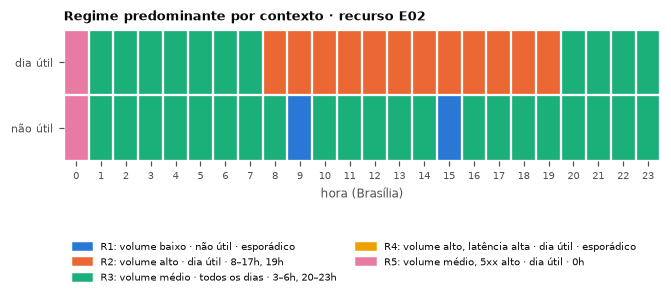

In [8]:
EXEMPLO = [r for r in recursos if rot(r) == "E02"][0]
d = slots[slots["recurso"] == EXEMPLO].pivot(index="tipo_dia", columns="hora", values="regime").loc[["util", "nao_util"]]
k = int(regimes.loc[rot(EXEMPLO), "k"])
fig, ax = plt.subplots(figsize=(7.0, 1.55))
ax.imshow(d.to_numpy(), aspect="auto", cmap=ListedColormap(CORES[:k]), vmin=-0.5, vmax=k - 0.5)
ax.set_yticks(range(2))
ax.set_yticklabels([NOMES_DIA[t] for t in d.index])
ax.set_xticks(range(24))
ax.set_xticklabels(range(24), fontsize=6.5)
ax.set_xlabel("hora (Brasília)")
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", length=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CORES[c], label=nomes_todos[rot(EXEMPLO)][c]) for c in range(k)],
          loc="upper left", bbox_to_anchor=(0, -0.55), ncol=2, fontsize=6.5)
ax.set_title(f"Regime predominante por contexto · recurso {rot(EXEMPLO)}", loc="left")
salvar(fig, "fig_regimes_contexto")
plt.show()

In [9]:
regimes.to_csv(RESULTADOS / "03_regimes.csv")
kw.to_csv(RESULTADOS / "03_kruskal.csv", index=False)
tab_kw.to_csv(RESULTADOS / "03_kruskal_resumo.csv")
slots.to_csv(RESULTADOS / "03_regime_por_contexto.csv", index=False)
salvar_json(dict(frac_kw_sig=float(kw["sig"].mean()), eps2_mediano=kw.groupby("indicador")["eps2"].median().to_dict(),
                 k_mediana=float(regimes["k"].median()), silhouette_medio=float(regimes["silhouette"].mean()),
                 nomes=nomes_todos), "03_resumo.json")